# KNN
Date:- 20/8/2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

Dataset is taen from : https://www.kaggle.com/datasets/hnazari8665/tipscsv

In [2]:
df=pd.read_csv('/content/drive/MyDrive/SEM 5/DMPM LAB/tips.csv')

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [5]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [6]:
df.isnull().sum()

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


<Axes: title={'center': 'total_bill'}, xlabel='sex'>

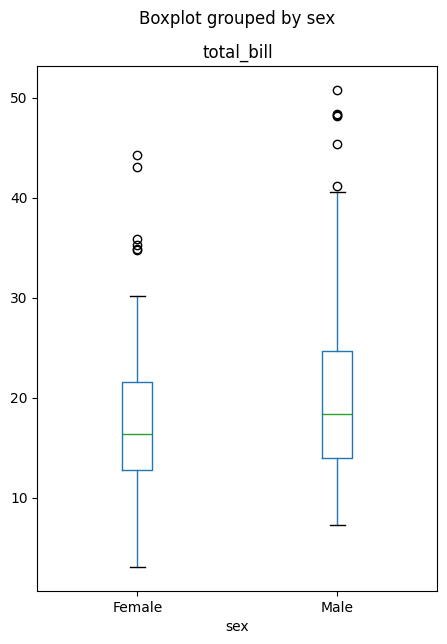

In [7]:
df.boxplot(by='sex',column='total_bill',grid=False,figsize=(5,7))

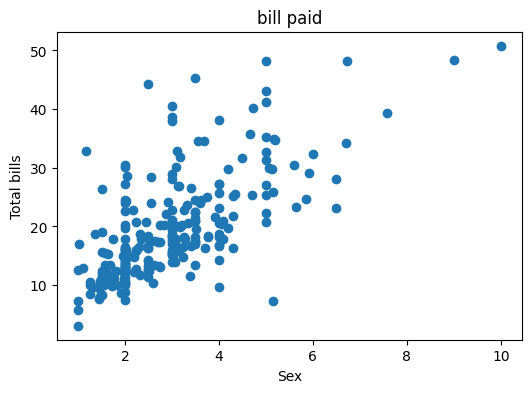

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df['tip'], df['total_bill'])
plt.xlabel('Sex')
plt.ylabel('Total bills')
plt.title('bill paid')
plt.show()

### Data Preprocessing for KNN

Before applying KNN, we need to convert categorical features into numerical representation using one-hot encoding. We will then define our features (X) and target (y), and split the data into training and testing sets.

In [9]:
categorical_features = ['smoker', 'day', 'time', 'size']
numerical_features = ['total_bill', 'tip']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

X = df.drop('sex', axis=1)
y = df['sex']

y = y.map({'Male': 0, 'Female': 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preprocessing complete. Shapes of training and testing sets:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

Data preprocessing complete. Shapes of training and testing sets:
X_train: (195, 6), y_train: (195,)
X_test: (49, 6), y_test: (49,)


### K-Nearest Neighbors (KNN) Implementation

Now, we will implement the KNN algorithm using `KNeighborsClassifier` from scikit-learn. We'll create a pipeline that first applies the preprocessing steps and then trains the KNN model. Finally, we'll evaluate the model's performance.

In [10]:
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)

y_pred = knn_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"KNN Model Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(report)

KNN Model Accuracy: 0.5918

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.83      0.71        30
           1       0.44      0.21      0.29        19

    accuracy                           0.59        49
   macro avg       0.53      0.52      0.50        49
weighted avg       0.55      0.59      0.55        49

